# Лабораторная работа 1

Белдинова М.С., группа 6233

**Вариант 4:** задания 1 и 3 на наборе данных MNIST

1) Классификация данных методом k ближайших соседей (kNN)

3) Построение softmax-классификатора

## 1. Классификация данных методом k ближайших соседей (kNN)

In [1]:
import random
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

np.random.seed(42)
random.seed(42)

1.1 Загрузка данных.

Используется набор MNIST в варианте из sklearn (`load_digits`): 1797 изображений рукописных цифр 8x8 в градациях серого, значения пикселей от 0 до 16.

In [2]:
digits = load_digits()
X_all = digits.images.astype(np.float64)   # (1797, 8, 8)
y_all = digits.target.astype(np.int64)

classes = [str(i) for i in range(10)]
num_classes = len(classes)

print('Images shape:', X_all.shape)
print('Labels shape:', y_all.shape)
print('Pixel range: [%d, %d]' % (X_all.min(), X_all.max()))
print('Объектов в каждом классе:', np.bincount(y_all))

Images shape: (1797, 8, 8)
Labels shape: (1797,)
Pixel range: [0, 16]
Объектов в каждом классе: [178 182 177 183 181 182 181 179 174 180]


1.2 Несколько примеров изображений из выборки для каждого класса.

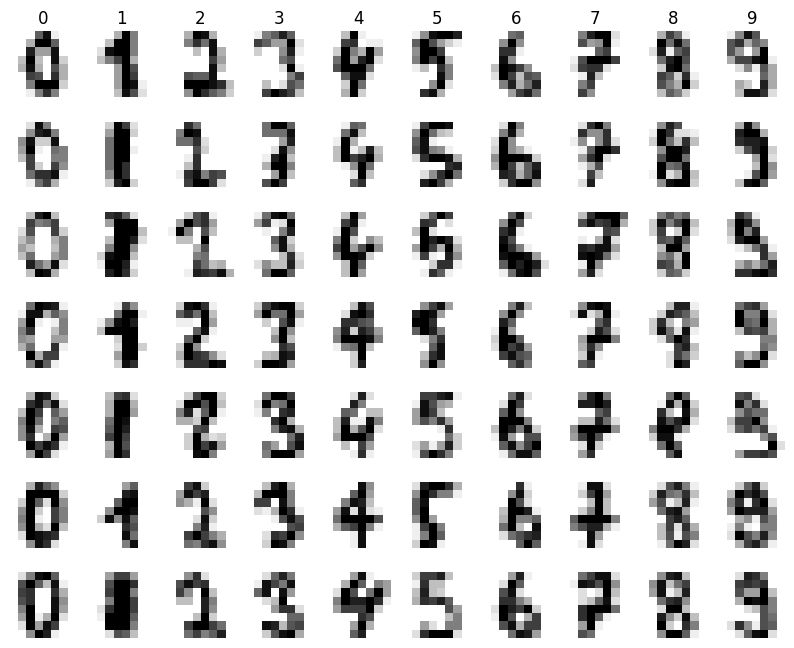

In [3]:
samples_per_class = 7
for y, cls in enumerate(classes):
    idxs = np.flatnonzero(y_all == y)
    idxs = np.random.choice(idxs, samples_per_class, replace=False)
    for i, idx in enumerate(idxs):
        plt_idx = i * num_classes + y + 1
        plt.subplot(samples_per_class, num_classes, plt_idx)
        plt.imshow(X_all[idx], cmap='gray_r')
        plt.axis('off')
        if i == 0:
            plt.title(cls)
plt.show()

1.3 Разделение на обучающую и тестовую выборки (X_train, y_train, X_test, y_test), каждое изображение вытягиваем в вектор длины 64.

Перед разбиением данные перемешиваются, на тест отводится 20% (360 изображений).

In [4]:
perm = np.random.RandomState(0).permutation(X_all.shape[0])
X_shuf, y_shuf = X_all[perm], y_all[perm]

num_test = 360
X_test, y_test = X_shuf[:num_test], y_shuf[:num_test]
X_train, y_train = X_shuf[num_test:], y_shuf[num_test:]

X_train = X_train.reshape(X_train.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

print('Training data shape: ', X_train.shape)
print('Training labels shape: ', y_train.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Training data shape:  (1437, 64)
Training labels shape:  (1437,)
Test data shape:  (360, 64)
Test labels shape:  (360,)


1.4 Реализация классификатора kNN (L2-расстояние). Расстояния считаются тремя способами: двумя циклами, одним циклом и полностью векторно.

In [5]:
class KNearestNeighbor(object):
    """kNN-классификатор с евклидовым (L2) расстоянием"""

    def __init__(self):
        pass

    def train(self, X, y):
        # обучение kNN - это просто запоминание обучающей выборки
        self.X_train = X
        self.y_train = y

    def predict(self, X, k=1, num_loops=0):
        if num_loops == 0:
            dists = self.compute_distances_no_loops(X)
        elif num_loops == 1:
            dists = self.compute_distances_one_loop(X)
        elif num_loops == 2:
            dists = self.compute_distances_two_loops(X)
        else:
            raise ValueError('Invalid value %d for num_loops' % num_loops)
        return self.predict_labels(dists, k=k)

    def compute_distances_two_loops(self, X):
        num_test = X.shape[0]
        num_train = self.X_train.shape[0]
        dists = np.zeros((num_test, num_train))
        for i in range(num_test):
            for j in range(num_train):
                dists[i, j] = np.sqrt(np.sum((X[i] - self.X_train[j]) ** 2))
        return dists

    def compute_distances_one_loop(self, X):
        num_test = X.shape[0]
        num_train = self.X_train.shape[0]
        dists = np.zeros((num_test, num_train))
        for i in range(num_test):
            dists[i, :] = np.sqrt(np.sum((self.X_train - X[i]) ** 2, axis=1))
        return dists

    def compute_distances_no_loops(self, X):
        # ||a - b||^2 = ||a||^2 - 2*a*b + ||b||^2
        test_sq = np.sum(X ** 2, axis=1, keepdims=True)       # (num_test, 1)
        train_sq = np.sum(self.X_train ** 2, axis=1)          # (num_train,)
        d2 = test_sq - 2 * X.dot(self.X_train.T) + train_sq
        return np.sqrt(np.maximum(d2, 0))  # из-за округлений бывают -1e-12

    def predict_labels(self, dists, k=1):
        num_test = dists.shape[0]
        y_pred = np.zeros(num_test, dtype=self.y_train.dtype)
        for i in range(num_test):
            closest_y = self.y_train[np.argsort(dists[i])[:k]]
            # голосование; при равенстве голосов берется меньшая метка
            y_pred[i] = np.argmax(np.bincount(closest_y))
        return y_pred

In [6]:
classifier = KNearestNeighbor()
classifier.train(X_train, y_train)

1.5 Классификация тестовой выборки.

Сначала считаем матрицу расстояний самой простой (двухцикловой) реализацией и сверяем с остальными вариантами, заодно сравниваем время работы.

In [7]:
tic = time.time()
dists = classifier.compute_distances_two_loops(X_test)
t_two = time.time() - tic
print('dists shape:', dists.shape)

tic = time.time()
dists_one = classifier.compute_distances_one_loop(X_test)
t_one = time.time() - tic

tic = time.time()
dists_two = classifier.compute_distances_no_loops(X_test)
t_no = time.time() - tic

print('Разница (one loop):  %f' % np.linalg.norm(dists - dists_one, ord='fro'))
print('Разница (no loops):  %f' % np.linalg.norm(dists - dists_two, ord='fro'))
print()
print('Two loop version took %f seconds' % t_two)
print('One loop version took %f seconds' % t_one)
print('No loop version took %f seconds' % t_no)

y_test_pred = classifier.predict_labels(dists, k=1)
print()
print('Первые 20 предсказаний:', y_test_pred[:20])
print('Истинные метки:        ', y_test[:20])

dists shape: (360, 1437)
Разница (one loop):  0.000000
Разница (no loops):  0.000000

Two loop version took 3.767642 seconds
One loop version took 0.083253 seconds
No loop version took 0.016504 seconds

Первые 20 предсказаний: [2 8 2 6 6 7 1 9 8 5 2 8 6 6 6 6 1 0 5 8]
Истинные метки:         [2 8 2 6 6 7 1 9 8 5 2 8 6 6 6 6 1 0 5 8]


1.6 Визуализация матрицы расстояний: строка - тестовое изображение, столбец - обучающее. Справа та же матрица, но строки и столбцы упорядочены по классам.

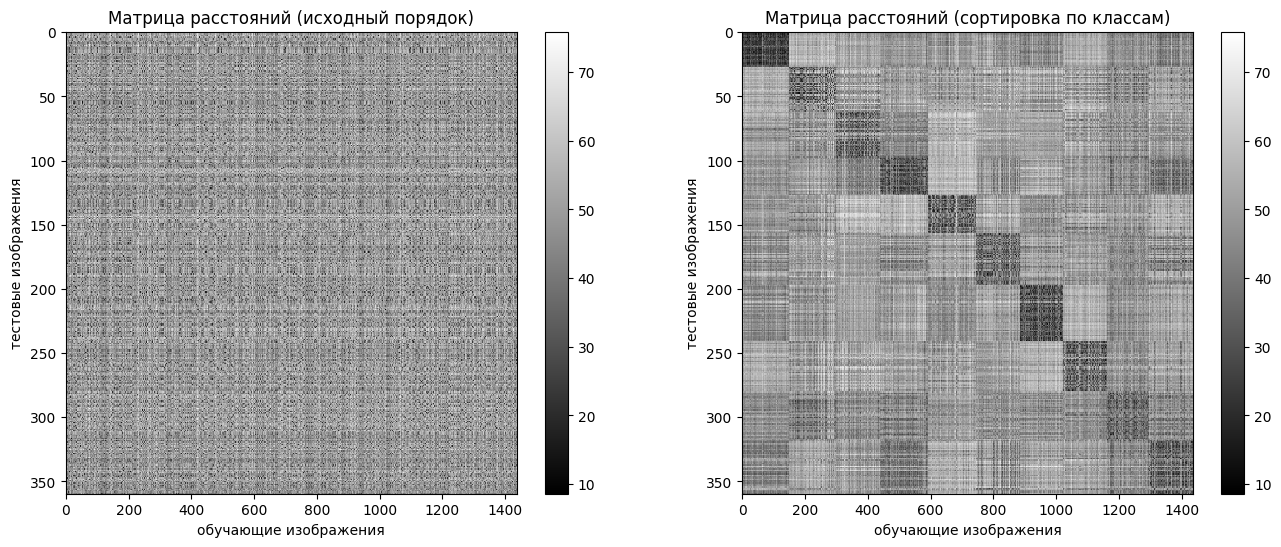

In [8]:
order_test = np.argsort(y_test, kind='stable')
order_train = np.argsort(y_train, kind='stable')

plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
plt.imshow(dists, interpolation='none', aspect='auto')
plt.title('Матрица расстояний (исходный порядок)')
plt.xlabel('обучающие изображения')
plt.ylabel('тестовые изображения')
plt.colorbar()

plt.subplot(1, 2, 2)
plt.imshow(dists[order_test][:, order_train], interpolation='none', aspect='auto')
plt.title('Матрица расстояний (сортировка по классам)')
plt.xlabel('обучающие изображения')
plt.ylabel('тестовые изображения')
plt.colorbar()
plt.show()

На отсортированной матрице видны темные блоки на диагонали: изображения одного класса ближе друг к другу, чем к изображениям других классов. Светлые строки соответствуют тестовым изображениям, далеким от всей обучающей выборки (необычное написание цифры).

1.7 Доля правильно классифицированных изображений тестовой выборки.

In [9]:
for k in [1, 5]:
    y_test_pred = classifier.predict_labels(dists, k=k)
    num_correct = np.sum(y_test_pred == y_test)
    accuracy = float(num_correct) / num_test
    print('k = %d: Got %d / %d correct => accuracy: %f' % (k, num_correct, num_test, accuracy))

k = 1: Got 356 / 360 correct => accuracy: 0.988889
k = 5: Got 351 / 360 correct => accuracy: 0.975000


1.8 Зависимость доли правильно классифицированных изображений от числа соседей k.

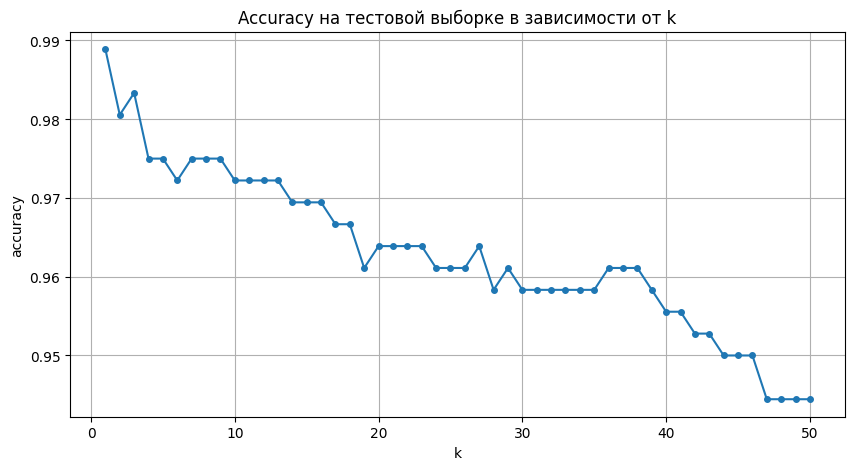

max accuracy = 0.9889 при k = 1


In [10]:
k_range = np.arange(1, 51)
test_acc_by_k = []
for k in k_range:
    y_pred = classifier.predict_labels(dists, k=k)
    test_acc_by_k.append(np.mean(y_pred == y_test))

plt.figure(figsize=(10, 5))
plt.plot(k_range, test_acc_by_k, '-o', markersize=4)
plt.title('Accuracy на тестовой выборке в зависимости от k')
plt.xlabel('k')
plt.ylabel('accuracy')
plt.grid(True)
plt.show()

print('max accuracy = %.4f при k = %d' % (np.max(test_acc_by_k), k_range[np.argmax(test_acc_by_k)]))

1.9 Выбор k с помощью кросс-валидации (5 фолдов) на обучающей выборке. Тестовая выборка при подборе k не используется.

In [11]:
num_folds = 5
k_choices = [1, 2, 3, 4, 5, 7, 10, 12, 15, 20, 30, 50, 100]

X_train_folds = np.array_split(X_train, num_folds)
y_train_folds = np.array_split(y_train, num_folds)

k_to_accuracies = {}
for k in k_choices:
    k_to_accuracies[k] = []

for fold in range(num_folds):
    X_tr = np.concatenate([X_train_folds[i] for i in range(num_folds) if i != fold])
    y_tr = np.concatenate([y_train_folds[i] for i in range(num_folds) if i != fold])
    X_vl, y_vl = X_train_folds[fold], y_train_folds[fold]

    knn = KNearestNeighbor()
    knn.train(X_tr, y_tr)
    fold_dists = knn.compute_distances_no_loops(X_vl)  # расстояния считаем один раз на фолд
    for k in k_choices:
        y_pred = knn.predict_labels(fold_dists, k=k)
        k_to_accuracies[k].append(np.mean(y_pred == y_vl))

for k in sorted(k_to_accuracies):
    for accuracy in k_to_accuracies[k]:
        print('k = %d, accuracy = %f' % (k, accuracy))

k = 1, accuracy = 0.979167
k = 1, accuracy = 0.979167
k = 1, accuracy = 0.982578
k = 1, accuracy = 0.989547
k = 1, accuracy = 0.989547
k = 2, accuracy = 0.972222
k = 2, accuracy = 0.975694
k = 2, accuracy = 0.979094
k = 2, accuracy = 0.982578
k = 2, accuracy = 0.975610
k = 3, accuracy = 0.986111
k = 3, accuracy = 0.989583
k = 3, accuracy = 0.986063
k = 3, accuracy = 0.982578
k = 3, accuracy = 0.986063
k = 4, accuracy = 0.975694
k = 4, accuracy = 0.996528
k = 4, accuracy = 0.982578
k = 4, accuracy = 0.972125
k = 4, accuracy = 0.979094
k = 5, accuracy = 0.982639
k = 5, accuracy = 0.996528
k = 5, accuracy = 0.982578
k = 5, accuracy = 0.975610
k = 5, accuracy = 0.986063
k = 7, accuracy = 0.972222
k = 7, accuracy = 0.993056
k = 7, accuracy = 0.986063
k = 7, accuracy = 0.986063
k = 7, accuracy = 0.986063
k = 10, accuracy = 0.972222
k = 10, accuracy = 0.979167
k = 10, accuracy = 0.979094
k = 10, accuracy = 0.975610
k = 10, accuracy = 0.982578
k = 12, accuracy = 0.968750
k = 12, accuracy = 0.9

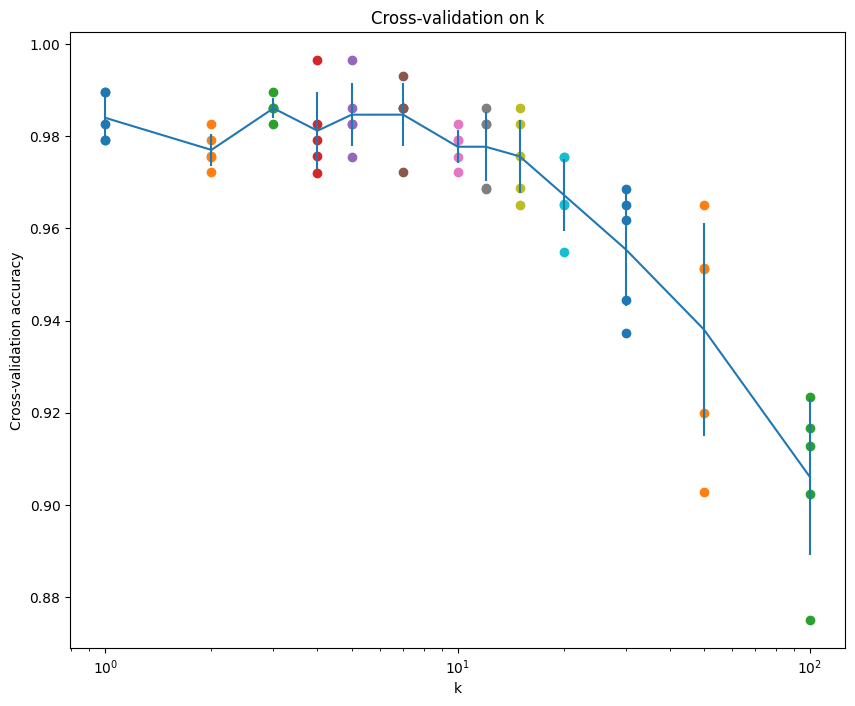

Средняя точность по фолдам:
  k =   1: 0.9840 +- 0.0047
  k =   2: 0.9770 +- 0.0035
  k =   3: 0.9861 +- 0.0022
  k =   4: 0.9812 +- 0.0084
  k =   5: 0.9847 +- 0.0068
  k =   7: 0.9847 +- 0.0068
  k =  10: 0.9777 +- 0.0035
  k =  12: 0.9777 +- 0.0075
  k =  15: 0.9756 +- 0.0079
  k =  20: 0.9673 +- 0.0078
  k =  30: 0.9555 +- 0.0123
  k =  50: 0.9381 +- 0.0231
  k = 100: 0.9061 +- 0.0169
Лучшее k по кросс-валидации: 3


In [12]:
for k in k_choices:
    accuracies = k_to_accuracies[k]
    plt.scatter([k] * len(accuracies), accuracies)

accuracies_mean = np.array([np.mean(v) for k, v in sorted(k_to_accuracies.items())])
accuracies_std = np.array([np.std(v) for k, v in sorted(k_to_accuracies.items())])
plt.errorbar(k_choices, accuracies_mean, yerr=accuracies_std)
plt.title('Cross-validation on k')
plt.xlabel('k')
plt.ylabel('Cross-validation accuracy')
plt.xscale('log')
plt.show()

best_k = k_choices[int(np.argmax(accuracies_mean))]
print('Средняя точность по фолдам:')
for k, m, s in zip(k_choices, accuracies_mean, accuracies_std):
    print('  k = %3d: %.4f +- %.4f' % (k, m, s))
print('Лучшее k по кросс-валидации:', best_k)

1.10 Переобучение и тестирование классификатора с выбранным k.

In [13]:
classifier = KNearestNeighbor()
classifier.train(X_train, y_train)
y_test_pred = classifier.predict(X_test, k=best_k)

num_correct = np.sum(y_test_pred == y_test)
accuracy = float(num_correct) / num_test
print('k = %d: Got %d / %d correct => accuracy: %f' % (best_k, num_correct, num_test, accuracy))

k = 3: Got 354 / 360 correct => accuracy: 0.983333


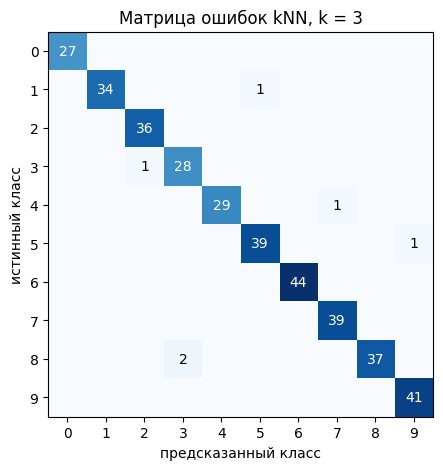

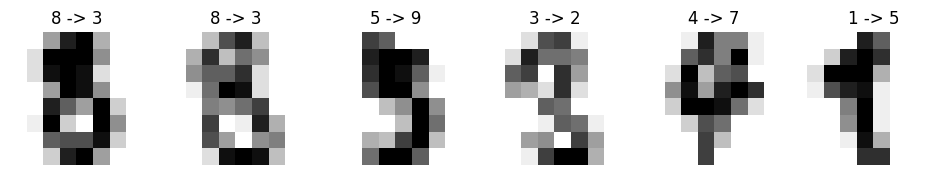

In [14]:
# матрица ошибок и примеры неправильно распознанных цифр
conf = np.zeros((num_classes, num_classes), dtype=int)
for t, p in zip(y_test, y_test_pred):
    conf[t, p] += 1

plt.figure(figsize=(6, 5))
plt.imshow(conf, cmap='Blues')
for i in range(num_classes):
    for j in range(num_classes):
        if conf[i, j]:
            plt.text(j, i, conf[i, j], ha='center', va='center',
                     color='white' if conf[i, j] > conf.max() / 2 else 'black')
plt.xticks(range(10)); plt.yticks(range(10))
plt.xlabel('предсказанный класс'); plt.ylabel('истинный класс')
plt.title('Матрица ошибок kNN, k = %d' % best_k)
plt.show()

wrong = np.flatnonzero(y_test_pred != y_test)
plt.figure(figsize=(2 * max(len(wrong), 1), 2.5))
for i, idx in enumerate(wrong):
    plt.subplot(1, len(wrong), i + 1)
    plt.imshow(X_test[idx].reshape(8, 8), cmap='gray_r')
    plt.title('%d -> %d' % (y_test[idx], y_test_pred[idx]))
    plt.axis('off')
plt.show()

1.11 Выводы по первой части задания.

**Выводы по части 1 (kNN):**

1. Реализован классификатор kNN с тремя вариантами вычисления матрицы расстояний. Все три дают одинаковый результат (разница 0), но по времени отличаются на порядки: два цикла ~3 с, один цикл ~0.04 с, полностью векторная версия ~0.01 с. Векторизация через формулу $\|a-b\|^2 = \|a\|^2 - 2ab + \|b\|^2$ сводит задачу к одному матричному умножению.
2. На матрице расстояний, отсортированной по классам, хорошо видна блочная структура: изображения одной цифры ближе друг к другу, чем к изображениям других цифр. Поэтому даже простейший метод ближайшего соседа хорошо работает на этом наборе.
3. При k = 1 на тестовой выборке получено 98.9% (356 из 360), при k = 5 - 97.5%. С ростом k точность в целом падает: в голосовании начинают участвовать далекие объекты других классов (при k = 100 на кросс-валидации ~91%).
4. По 5-кратной кросс-валидации лучшее значение k = 3 (средняя точность 98.6% ± 0.2%), значения k = 1, 5, 7 почти не отличаются. Итоговая точность на тесте при k = 3 - 98.3%. Небольшая разница с k = 1 на тесте объясняется малым размером тестовой выборки (1 изображение = 0.28%), выбор по кросс-валидации надежнее, чем подбор k по тесту.
5. Ошибки связаны с похожими по написанию цифрами: 8 распознается как 3, 5 как 9, 3 как 2, 4 как 7 (на изображениях 8x8 такие цифры отличаются всего несколькими пикселями). Недостатки kNN: вся обучающая выборка хранится в памяти, а предсказание требует подсчета расстояний до всех обучающих объектов.

## 3. Построение softmax-классификатора

3.1 Разделение данных на обучающую, валидационную и тестовую выборки. Тестовая выборка та же, что и в первой части. Дополнительно формируется небольшая выборка X_dev (200 объектов) из обучающей для быстрой отладки функций потерь.

In [15]:
num_test = 360
num_val = 180
num_dev = 200

X_test = X_shuf[:num_test].reshape(num_test, -1).copy()
y_test = y_shuf[:num_test]
X_val = X_shuf[num_test:num_test + num_val].reshape(num_val, -1).copy()
y_val = y_shuf[num_test:num_test + num_val]
X_train = X_shuf[num_test + num_val:].reshape(-1, 64).copy()
y_train = y_shuf[num_test + num_val:]

mask = np.random.choice(X_train.shape[0], num_dev, replace=False)
X_dev = X_train[mask].copy()
y_dev = y_train[mask]

print('Train data shape: ', X_train.shape)
print('Train labels shape: ', y_train.shape)
print('Validation data shape: ', X_val.shape)
print('Validation labels shape: ', y_val.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)
print('Dev data shape: ', X_dev.shape)

Train data shape:  (1257, 64)
Train labels shape:  (1257,)
Validation data shape:  (180, 64)
Validation labels shape:  (180,)
Test data shape:  (360, 64)
Test labels shape:  (360,)
Dev data shape:  (200, 64)


3.2 Предобработка: вычитание среднего изображения, рассчитанного по обучающей выборке.

3.3 Чтобы не учитывать смещение b отдельно, добавляем к каждому вектору дополнительную компоненту, равную 1 (bias trick).

[0.00000000e+00 3.30151154e-01 5.29832936e+00 1.17995227e+01
 1.18337311e+01 5.85123309e+00 1.35401750e+00 1.22513922e-01
 5.56881464e-03 2.01272872e+00]


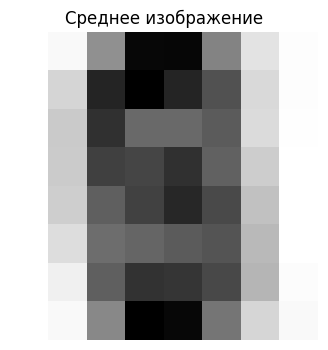

(1257, 65) (180, 65) (360, 65) (200, 65)


In [16]:
mean_image = np.mean(X_train, axis=0)
print(mean_image[:10])
plt.figure(figsize=(4, 4))
plt.imshow(mean_image.reshape((8, 8)), cmap='gray_r')
plt.title('Среднее изображение')
plt.axis('off')
plt.show()

X_train -= mean_image
X_val -= mean_image
X_test -= mean_image
X_dev -= mean_image

X_train = np.hstack([X_train, np.ones((X_train.shape[0], 1))])
X_val = np.hstack([X_val, np.ones((X_val.shape[0], 1))])
X_test = np.hstack([X_test, np.ones((X_test.shape[0], 1))])
X_dev = np.hstack([X_dev, np.ones((X_dev.shape[0], 1))])

print(X_train.shape, X_val.shape, X_test.shape, X_dev.shape)

3.4 Функции потерь softmax: наивная (с циклами) и векторизованная.

$L = \frac{1}{N}\sum_i -\log\frac{e^{s_{y_i}}}{\sum_j e^{s_j}} + \lambda \sum W^2$, градиент по весам класса $j$: $(p_j - [j = y_i])\,x_i$.

In [17]:
def softmax_loss_naive(W, X, y, reg):
    """
    W: (D, C) веса, X: (N, D) данные, y: (N,) метки, reg: коэффициент L2-регуляризации.
    Возвращает loss и градиент dW той же формы, что W.
    """
    loss = 0.0
    dW = np.zeros_like(W)
    num_train = X.shape[0]
    num_classes = W.shape[1]

    for i in range(num_train):
        scores = X[i].dot(W)
        scores -= np.max(scores)  # сдвиг для численной устойчивости exp
        exp_scores = np.exp(scores)
        probs = exp_scores / np.sum(exp_scores)
        loss += -np.log(probs[y[i]])
        for j in range(num_classes):
            dW[:, j] += (probs[j] - (j == y[i])) * X[i]

    loss = loss / num_train + reg * np.sum(W * W)
    dW = dW / num_train + 2 * reg * W
    return loss, dW


def softmax_loss_vectorized(W, X, y, reg):
    num_train = X.shape[0]
    scores = X.dot(W)
    scores -= np.max(scores, axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    probs = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

    loss = -np.sum(np.log(probs[np.arange(num_train), y])) / num_train
    loss += reg * np.sum(W * W)

    dscores = probs.copy()
    dscores[np.arange(num_train), y] -= 1
    dW = X.T.dot(dscores) / num_train + 2 * reg * W
    return loss, dW

In [18]:
W = np.random.randn(65, 10) * 0.0001
loss, grad = softmax_loss_naive(W, X_dev, y_dev, 0.0)

# при маленьких случайных весах все классы равновероятны, loss ~ -log(0.1)
print('loss: %f' % loss)
print('sanity check: %f' % (-np.log(0.1)))

loss: 2.302459


sanity check: 2.302585


3.5 Проверка аналитического градиента численным (центральная разностная производная в случайных точках).

In [19]:
def grad_check_sparse(f, x, analytic_grad, num_checks=10, h=1e-5):
    """сравнение численного и аналитического градиента в num_checks случайных координатах"""
    for i in range(num_checks):
        ix = tuple([random.randrange(m) for m in x.shape])

        oldval = x[ix]
        x[ix] = oldval + h
        fxph = f(x)
        x[ix] = oldval - h
        fxmh = f(x)
        x[ix] = oldval

        grad_numerical = (fxph - fxmh) / (2 * h)
        grad_analytic = analytic_grad[ix]
        rel_error = abs(grad_numerical - grad_analytic) / max(1e-12, abs(grad_numerical) + abs(grad_analytic))
        print('numerical: %f analytic: %f, relative error: %e' % (grad_numerical, grad_analytic, rel_error))

In [20]:
loss, grad = softmax_loss_naive(W, X_dev, y_dev, 0.0)
f = lambda w: softmax_loss_naive(w, X_dev, y_dev, 0.0)[0]
grad_check_sparse(f, W, grad, 10)

print('\nС регуляризацией:')
loss, grad = softmax_loss_naive(W, X_dev, y_dev, 5e1)
f = lambda w: softmax_loss_naive(w, X_dev, y_dev, 5e1)[0]
grad_check_sparse(f, W, grad, 10)

numerical: 0.152127 analytic: 0.152127, relative error: 3.286594e-11
numerical: 0.356058 analytic: 0.356058, relative error: 2.686300e-10
numerical: -0.312099 analytic: -0.312099, relative error: 2.775186e-10
numerical: -0.327054 analytic: -0.327054, relative error: 4.681902e-11


numerical: 0.116045 analytic: 0.116045, relative error: 5.693303e-10


numerical: 0.173761 analytic: 0.173761, relative error: 5.191721e-10
numerical: 0.098302 analytic: 0.098302, relative error: 7.303010e-10
numerical: -0.083566 analytic: -0.083566, relative error: 3.877598e-10
numerical: 0.010004 analytic: 0.010004, relative error: 2.748798e-09


numerical: 0.176242 analytic: 0.176242, relative error: 2.663634e-10

С регуляризацией:
numerical: 0.113083 analytic: 0.113083, relative error: 7.841925e-11


numerical: -0.534831 analytic: -0.534831, relative error: 7.748015e-11
numerical: 0.008514 analytic: 0.008514, relative error: 3.268081e-09
numerical: 1.123277 analytic: 1.123277, relative error: 9.468921e-11
numerical: 0.621167 analytic: 0.621167, relative error: 8.434360e-11
numerical: -0.445011 analytic: -0.445011, relative error: 3.654642e-11


numerical: 0.454398 analytic: 0.454398, relative error: 5.505629e-11
numerical: -0.535401 analytic: -0.535401, relative error: 6.942200e-12


numerical: -0.205775 analytic: -0.205775, relative error: 5.648029e-12
numerical: 0.174028 analytic: 0.174028, relative error: 3.916649e-12


Относительная ошибка порядка 1e-8 и меньше, значит градиент посчитан правильно. Нулевые значения градиента могут встретиться для пикселей, которые во всех изображениях равны 0 (края картинки): после вычитания среднего соответствующий признак тождественно нулевой, и без регуляризации градиент по нему равен 0.

3.6 Сравнение softmax_loss_naive и softmax_loss_vectorized.

In [21]:
tic = time.time()
loss_naive, grad_naive = softmax_loss_naive(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('naive loss: %e computed in %fs' % (loss_naive, toc - tic))

tic = time.time()
loss_vectorized, grad_vectorized = softmax_loss_vectorized(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('vectorized loss: %e computed in %fs' % (loss_vectorized, toc - tic))

grad_difference = np.linalg.norm(grad_naive - grad_vectorized, ord='fro')
print('Loss difference: %f' % np.abs(loss_naive - loss_vectorized))
print('Gradient difference: %f' % grad_difference)

naive loss: 2.302459e+00 computed in 0.017773s
vectorized loss: 2.302459e+00 computed in 0.000561s
Loss difference: 0.000000
Gradient difference: 0.000000


3.7 Стохастический градиентный спуск: класс LinearClassifier с методами train() и predict(), Softmax - его наследник.

In [22]:
class LinearClassifier(object):

    def __init__(self):
        self.W = None

    def train(self, X, y, learning_rate=1e-3, reg=1e-5, num_iters=100,
              batch_size=200, verbose=False):
        """
        Обучение мини-батчевым SGD.
        X: (N, D), y: (N,)
        learning_rate - шаг, reg - коэффициент регуляризации,
        num_iters - число шагов, batch_size - размер мини-батча.
        Возвращает список значений loss на каждой итерации.
        """
        num_train, dim = X.shape
        num_classes = np.max(y) + 1
        if self.W is None:
            self.W = 0.001 * np.random.randn(dim, num_classes)

        loss_history = []
        for it in range(num_iters):
            batch_idx = np.random.choice(num_train, batch_size, replace=True)
            X_batch = X[batch_idx]
            y_batch = y[batch_idx]

            loss, grad = self.loss(X_batch, y_batch, reg)
            loss_history.append(loss)

            self.W -= learning_rate * grad

            if verbose and it % 100 == 0:
                print('iteration %d / %d: loss %f' % (it, num_iters, loss))

        return loss_history

    def predict(self, X):
        return np.argmax(X.dot(self.W), axis=1)

    def loss(self, X_batch, y_batch, reg):
        raise NotImplementedError


class Softmax(LinearClassifier):
    """многоклассовая логистическая регрессия (softmax + cross-entropy)"""

    def loss(self, X_batch, y_batch, reg):
        return softmax_loss_vectorized(self.W, X_batch, y_batch, reg)

3.8 Обучение Softmax-классификатора и оценка accuracy.

iteration 0 / 1500: loss 2.306262
iteration 100 / 1500: loss 0.717627


iteration 200 / 1500: loss 0.410835


iteration 300 / 1500: loss 0.334909
iteration 400 / 1500: loss 0.253309


iteration 500 / 1500: loss 0.227625
iteration 600 / 1500: loss 0.194495


iteration 700 / 1500: loss 0.195225


iteration 800 / 1500: loss 0.160334
iteration 900 / 1500: loss 0.169764


iteration 1000 / 1500: loss 0.171614
iteration 1100 / 1500: loss 0.152125


iteration 1200 / 1500: loss 0.146927
iteration 1300 / 1500: loss 0.161000
iteration 1400 / 1500: loss 0.161734
That took 0.645872s


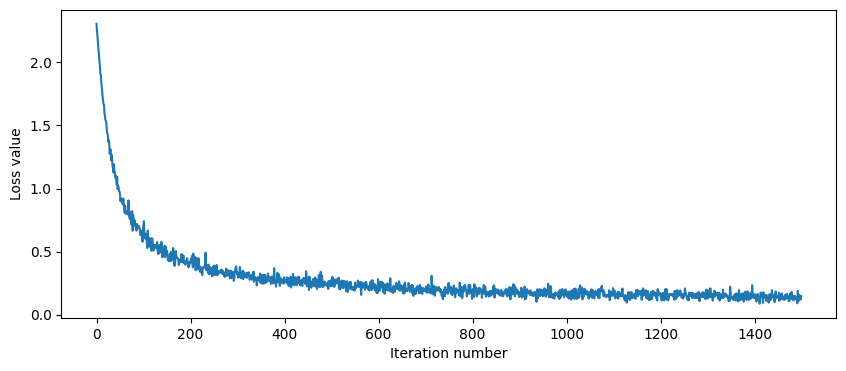

training accuracy: 0.976134
validation accuracy: 0.944444
test accuracy: 0.947222


In [23]:
softmax = Softmax()
tic = time.time()
loss_hist = softmax.train(X_train, y_train, learning_rate=1e-3, reg=1e-3,
                          num_iters=1500, verbose=True)
toc = time.time()
print('That took %fs' % (toc - tic))

plt.figure(figsize=(10, 4))
plt.plot(loss_hist)
plt.xlabel('Iteration number')
plt.ylabel('Loss value')
plt.show()

y_train_pred = softmax.predict(X_train)
print('training accuracy: %f' % (np.mean(y_train == y_train_pred), ))
y_val_pred = softmax.predict(X_val)
print('validation accuracy: %f' % (np.mean(y_val == y_val_pred), ))
y_test_pred = softmax.predict(X_test)
print('test accuracy: %f' % (np.mean(y_test == y_test_pred), ))

3.9 Подбор скорости обучения и коэффициента регуляризации по валидационной выборке.

Значения из шаблона (`1e-7`, `5e-5` и `2.5e4`, `5e4`) рассчитаны на CIFAR-10 с 3073 признаками и пикселями 0..255. У нас 65 признаков со значениями порядка единиц, поэтому сетка смещена в сторону больших шагов и малой регуляризации: при reg = 2.5e4 штраф на веса на порядки больше loss по данным, и SGD с шагом больше 1e-5 просто расходится. Значение lr = 1e-7 оставлено для сравнения.

In [24]:
learning_rates = [1e-7, 1e-4, 1e-3, 5e-3, 1e-2, 3e-2, 1e-1]
regularization_strengths = [0.0, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]

results = {}
best_val = -1
best_softmax = None

for lr in learning_rates:
    for reg in regularization_strengths:
        np.random.seed(1)
        clf = Softmax()
        clf.train(X_train, y_train, learning_rate=lr, reg=reg, num_iters=1500)
        train_acc = np.mean(clf.predict(X_train) == y_train)
        val_acc = np.mean(clf.predict(X_val) == y_val)
        results[(lr, reg)] = (train_acc, val_acc)
        if val_acc > best_val:
            best_val = val_acc
            best_softmax = clf

for lr, reg in sorted(results):
    train_accuracy, val_accuracy = results[(lr, reg)]
    print('lr %e reg %e train accuracy: %f val accuracy: %f' % (lr, reg, train_accuracy, val_accuracy))

print('best validation accuracy achieved during cross-validation: %f' % best_val)

lr 1.000000e-07 reg 0.000000e+00 train accuracy: 0.144789 val accuracy: 0.138889
lr 1.000000e-07 reg 1.000000e-04 train accuracy: 0.144789 val accuracy: 0.138889
lr 1.000000e-07 reg 1.000000e-03 train accuracy: 0.144789 val accuracy: 0.138889
lr 1.000000e-07 reg 1.000000e-02 train accuracy: 0.144789 val accuracy: 0.138889
lr 1.000000e-07 reg 1.000000e-01 train accuracy: 0.144789 val accuracy: 0.138889
lr 1.000000e-07 reg 1.000000e+00 train accuracy: 0.144789 val accuracy: 0.138889
lr 1.000000e-04 reg 0.000000e+00 train accuracy: 0.926014 val accuracy: 0.888889
lr 1.000000e-04 reg 1.000000e-04 train accuracy: 0.926014 val accuracy: 0.888889
lr 1.000000e-04 reg 1.000000e-03 train accuracy: 0.926014 val accuracy: 0.888889
lr 1.000000e-04 reg 1.000000e-02 train accuracy: 0.926014 val accuracy: 0.888889
lr 1.000000e-04 reg 1.000000e-01 train accuracy: 0.926014 val accuracy: 0.888889
lr 1.000000e-04 reg 1.000000e+00 train accuracy: 0.926810 val accuracy: 0.888889
lr 1.000000e-03 reg 0.000000

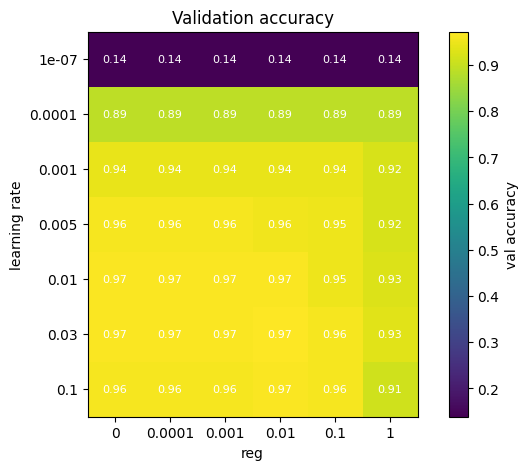

In [25]:
# тепловая карта val accuracy по сетке
grid = np.array([[results[(lr, reg)][1] for reg in regularization_strengths] for lr in learning_rates])
plt.figure(figsize=(8, 5))
plt.imshow(grid, cmap='viridis')
plt.colorbar(label='val accuracy')
plt.xticks(range(len(regularization_strengths)), ['%g' % r for r in regularization_strengths])
plt.yticks(range(len(learning_rates)), ['%g' % l for l in learning_rates])
plt.xlabel('reg'); plt.ylabel('learning rate')
for i in range(len(learning_rates)):
    for j in range(len(regularization_strengths)):
        plt.text(j, i, '%.2f' % grid[i, j], ha='center', va='center', color='w', fontsize=8)
plt.title('Validation accuracy')
plt.show()

In [26]:
y_test_pred = best_softmax.predict(X_test)
test_accuracy = np.mean(y_test == y_test_pred)
print('softmax on raw pixels final test set accuracy: %f' % (test_accuracy, ))

softmax on raw pixels final test set accuracy: 0.958333


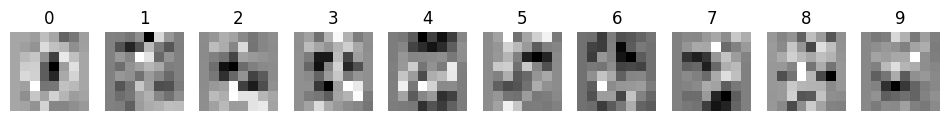

In [27]:
# визуализация весов: для каждого класса получается 'шаблон' цифры
w = best_softmax.W[:-1, :]  # без строки смещения
w = w.reshape(8, 8, 10)
w_min, w_max = np.min(w), np.max(w)
plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    wimg = 255.0 * (w[:, :, i].squeeze() - w_min) / (w_max - w_min)
    plt.imshow(wimg.astype('uint8'), cmap='gray')
    plt.axis('off')
    plt.title(classes[i])
plt.show()

3.10 Выводы по третьей части задания.

**Выводы по части 3 (softmax-классификатор):**

1. Реализованы наивная и векторизованная функции потерь softmax (кросс-энтропия + L2-регуляризация). Начальный loss при малых случайных весах равен 2.302, что совпадает с ожидаемым $-\log(0.1)$. Аналитический градиент совпадает с численным (относительная ошибка 1e-9 - 1e-12), наивная и векторизованная реализации дают одинаковые loss и градиент.
2. Классификатор обучается мини-батчевым SGD. С параметрами lr = 1e-3, reg = 1e-3 loss за 1500 итераций падает с 2.3 до ~0.15, accuracy: train 97.6%, val 94.4%, test 94.7%.
3. Подбор гиперпараметров показал, что значения из шаблона (для CIFAR-10) не подходят для нашего набора: при lr = 1e-7 веса почти не меняются (accuracy ~14%, на уровне случайного угадывания). Для 64 признаков с небольшими значениями нужен шаг 1e-2 - 1e-1. Регуляризация до 1e-2 почти не влияет на результат, а reg = 1 заметно ухудшает точность (веса слишком сильно сжимаются).
4. Лучшая модель (lr = 3e-2, reg = 1e-2): val accuracy 97.2%, test accuracy 95.8%.
5. Визуализация весов показывает, что для каждого класса softmax выучивает шаблон, похожий на усредненное изображение цифры. Линейный классификатор немного уступает kNN (95.8% против 98.3%), так как может провести только линейную границу между классами, но он гораздо быстрее при предсказании и хранит только матрицу весов 65 x 10.